# Predictive Automobile Price Modeling Using Machine Learning and Deep Learning
## Comparative Analysis and Data Preparation Techniques

This notebook demonstrates a end-to-end data science pipeline for predicting car prices using the `CarPrice_Assignment.csv` dataset. 
It includes advanced data preparation, feature engineering, model training across 5 algorithms (Ridge, Random Forest, Extra Trees, Gradient Boosting, Deep Learning ANN), and comparative evaluation.

In [1]:
# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    mean_absolute_error, 
    mean_squared_error, 
    r2_score, 
    mean_absolute_percentage_error
)

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.ensemble import VotingRegressor

# Set seed for reproducibility
np.random.seed(42)
torch.manual_seed(42)

## 2. Data Preparation & Feature Engineering

Key steps implemented:
1. **Brand Extraction & Typo Correction**: Extracting manufacturer name from `CarName` and fixing typos (`maxda`, `vokswagen`, `porcshz`, etc.).
2. **Ordinal Mapping**: Mapping text numbers (`two`, `four`, etc.) in `doornumber` and `cylindernumber` to integers.
3. **Feature Engineering**: Creating `avg_mpg` and `power_to_weight` ratio features.
4. **Column Transformations**: Applying `StandardScaler` for numeric columns and `OneHotEncoder` for nominal categorical variables.

In [2]:
# Load dataset
df = pd.read_csv('CarPrice_Assignment.csv')

# Extract Brand Name & Clean Typos
df['brand'] = df['CarName'].apply(lambda x: x.split(' ')[0].lower())
brand_map = {
    'maxda': 'mazda',
    'porcshz': 'porsche',
    'toyouta': 'toyota',
    'vokswagen': 'volkswagen',
    'vw': 'volkswagen'
}
df['brand'] = df['brand'].replace(brand_map)
df_clean = df.drop(columns=['car_ID', 'CarName'])

# Ordinal Mapping
door_map = {'two': 2, 'four': 4}
num_map = {'two': 2, 'three': 3, 'four': 4, 'five': 5, 'six': 6, 'eight': 8, 'twelve': 12}
df_clean['doornumber'] = df_clean['doornumber'].map(door_map)
df_clean['cylindernumber'] = df_clean['cylindernumber'].map(num_map)

# Feature Engineering
df_clean['avg_mpg'] = (df_clean['citympg'] + df_clean['highwaympg']) / 2
df_clean['power_to_weight'] = df_clean['horsepower'] / df_clean['curbweight']

X = df_clean.drop(columns=['price'])
y = df_clean['price']

categorical_cols = X.select_dtypes(include=['object', 'str']).columns.tolist()
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Preprocessing Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_cols)
    ]
)

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

if hasattr(X_train_proc, 'toarray'):
    X_train_proc = X_train_proc.toarray()
    X_test_proc = X_test_proc.toarray()

print(f'Processed X_train shape: {X_train_proc.shape}')

Processed X_train shape: (164, 62)


## 3. Model Building & Training

We train 5 distinct machine learning & deep learning architectures:
1. **Ridge Regression** (Linear Baseline)
2. **Random Forest Regressor** (Bagging Ensemble)
3. **Extra Trees Regressor** (Extremely Randomized Trees)
4. **Gradient Boosting Regressor** (Boosting Ensemble)
5. **Deep Learning (ANN)** (Multi-Layer Perceptron in PyTorch with BatchNorm & Dropout)

In [3]:
results = {}

def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    
    # Calculate percentage-based error metrics
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    rmspe = np.sqrt(np.mean(np.square((y_true - y_pred) / y_true))) * 100
    
    results[name] = {
        'MAE': mae, 
        'RMSE': rmse, 
        'R2': r2, 
        'MAPE (%)': mape, 
        'RMSPE (%)': rmspe
    }
    
    print(f"{name} -> MAE: {mae:.2f}, RMSE: {rmse:.2f}, R2: {r2:.4f} | MAPE: {mape:.2f}%, RMSPE: {rmspe:.2f}%")

# 1. Ridge Regression
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_proc, y_train)
evaluate_model('Ridge Regression', y_test, ridge.predict(X_test_proc))

# 2. Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train_proc, y_train)
evaluate_model('Random Forest', y_test, rf.predict(X_test_proc))

# 3. Gradient Boosting
gb = GradientBoostingRegressor(n_estimators=100, random_state=42)
gb.fit(X_train_proc, y_train)
evaluate_model('Gradient Boosting', y_test, gb.predict(X_test_proc))

# 4. Extra Trees
et = ExtraTreesRegressor(n_estimators=100, random_state=42)
et.fit(X_train_proc, y_train)
evaluate_model('Extra Trees', y_test, et.predict(X_test_proc))

# 5. Deep Learning (ANN with PyTorch)
input_dim = X_train_proc.shape[1]

class CarPriceANN(nn.Module):
    def __init__(self, input_dim):
        super(CarPriceANN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
        
    def forward(self, x):
        return self.net(x)

y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1))

X_tr_t = torch.tensor(X_train_proc, dtype=torch.float32)
y_tr_t = torch.tensor(y_train_scaled, dtype=torch.float32)
X_te_t = torch.tensor(X_test_proc, dtype=torch.float32)

ann = CarPriceANN(input_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(ann.parameters(), lr=0.01, weight_decay=1e-4)

ann.train()
for epoch in range(300):
    optimizer.zero_grad()
    outputs = ann(X_tr_t)
    loss = criterion(outputs, y_tr_t)
    loss.backward()
    optimizer.step()

ann.eval()
with torch.no_grad():
    y_pred_ann_scaled = ann(X_te_t).numpy()
    y_pred_ann = y_scaler.inverse_transform(y_pred_ann_scaled).flatten()

evaluate_model('Deep Learning (ANN)', y_test, y_pred_ann)

voting_ens = VotingRegressor(estimators=[
    ('rf', rf),
    ('gb', gb),
    ('et', et)
])

# Fit Ensemble Model
voting_ens.fit(X_train_proc, y_train)
y_pred_ens = voting_ens.predict(X_test_proc)

# Evaluate Meta-Ensemble
evaluate_model('Tree Ensemble (RF+GB+ET)', y_test, y_pred_ens)



Ridge Regression -> MAE: 2029.33, RMSE: 2894.18, R2: 0.8939 | MAPE: 17.70%, RMSPE: 26.35%


Random Forest -> MAE: 1293.19, RMSE: 1817.27, R2: 0.9582 | MAPE: 9.43%, RMSPE: 11.48%
Gradient Boosting -> MAE: 1582.48, RMSE: 2237.39, R2: 0.9366 | MAPE: 10.75%, RMSPE: 12.92%


Extra Trees -> MAE: 1361.61, RMSE: 2064.08, R2: 0.9460 | MAPE: 9.79%, RMSPE: 11.86%


Deep Learning (ANN) -> MAE: 1217.63, RMSE: 2048.41, R2: 0.9468 | MAPE: 9.28%, RMSPE: 11.54%


Tree Ensemble (RF+GB+ET) -> MAE: 1314.26, RMSE: 1847.94, R2: 0.9567 | MAPE: 9.29%, RMSPE: 11.22%


## 4. Results & Comparative Evaluation

In [4]:
# Model Performance Summary
updated_res_df = pd.DataFrame(results).T.sort_values(by='R2', ascending=False)
print("--- Final Comparative Summary (Including Meta-Ensemble) ---")
display(updated_res_df)

# Top Feature Importances from Random Forest
encoded_cat_cols = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)
all_feature_names = numerical_cols + list(encoded_cat_cols)
importances1 = pd.Series(rf.feature_importances_, index=all_feature_names).sort_values(ascending=False).head(10)
importances2 = pd.Series(gb.feature_importances_, index=all_feature_names).sort_values(ascending=False).head(10)
importances3 = pd.Series(et.feature_importances_, index=all_feature_names).sort_values(ascending=False).head(10)
# Approximate Voting Regressor feature importance
ensemble_importances = np.mean(
    [rf.feature_importances_, gb.feature_importances_, et.feature_importances_],
    axis=0
)

importances4 = pd.Series(
    ensemble_importances,
    index=all_feature_names
).sort_values(ascending=False).head(10)


print("\n--- Top 10 Most Important Features by random forest ---")
print(importances1)
print("\n--- Top 10 Most Important Features by gradient boosting ---")
print(importances2)

--- Final Comparative Summary (Including Meta-Ensemble) ---


,MAE,RMSE,R2,MAPE (%),RMSPE (%)
Random Forest,1293.188793,1817.266283,0.958167,9.426352,11.479841
Tree Ensemble (RF+GB+ET),1314.260305,1847.939955,0.956743,9.292588,11.215733
Deep Learning (ANN),1217.633884,2048.408356,0.946849,9.275816,11.536278
Extra Trees,1361.614098,2064.082358,0.946032,9.792159,11.862850
Gradient Boosting,1582.477981,2237.393241,0.936589,10.753260,12.923003
Ridge Regression,2029.330265,2894.176147,0.893896,17.704136,26.354290



--- Top 10 Most Important Features by random forest ---
enginesize         0.553491
curbweight         0.271019
avg_mpg            0.043167
horsepower         0.032450
highwaympg         0.023607
carwidth           0.014554
carlength          0.007472
power_to_weight    0.005881
brand_bmw          0.005849
peakrpm            0.005129
dtype: float64

--- Top 10 Most Important Features by gradient boosting ---
enginesize        0.605129
curbweight        0.175871
highwaympg        0.049264
horsepower        0.044852
cylindernumber    0.023597
wheelbase         0.019538
carwidth          0.015155
carlength         0.008796
brand_bmw         0.008071
avg_mpg           0.007182
dtype: float64


In [5]:
print("\n--- Top 10 Most Important Features by extra trees ---")
print(importances3)
print("\n--- Top 10 Most Important Features by Ensemble ---")
print(importances4)


--- Top 10 Most Important Features by extra trees ---
enginesize             0.195710
curbweight             0.149644
avg_mpg                0.087738
cylindernumber         0.082114
citympg                0.072757
drivewheel_rwd         0.070977
horsepower             0.067565
highwaympg             0.048708
carwidth               0.036046
enginelocation_rear    0.018894
dtype: float64

--- Top 10 Most Important Features by Ensemble ---
enginesize        0.451443
curbweight        0.198845
horsepower        0.048289
avg_mpg           0.046029
highwaympg        0.040527
cylindernumber    0.035709
citympg           0.027491
drivewheel_rwd    0.024956
carwidth          0.021918
wheelbase         0.012799
dtype: float64


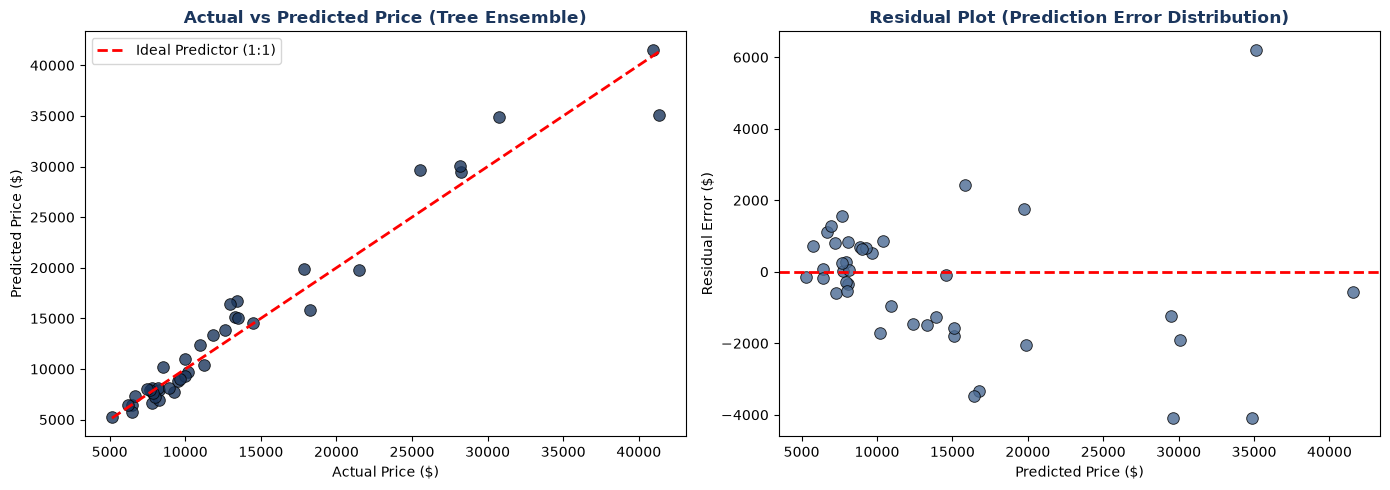

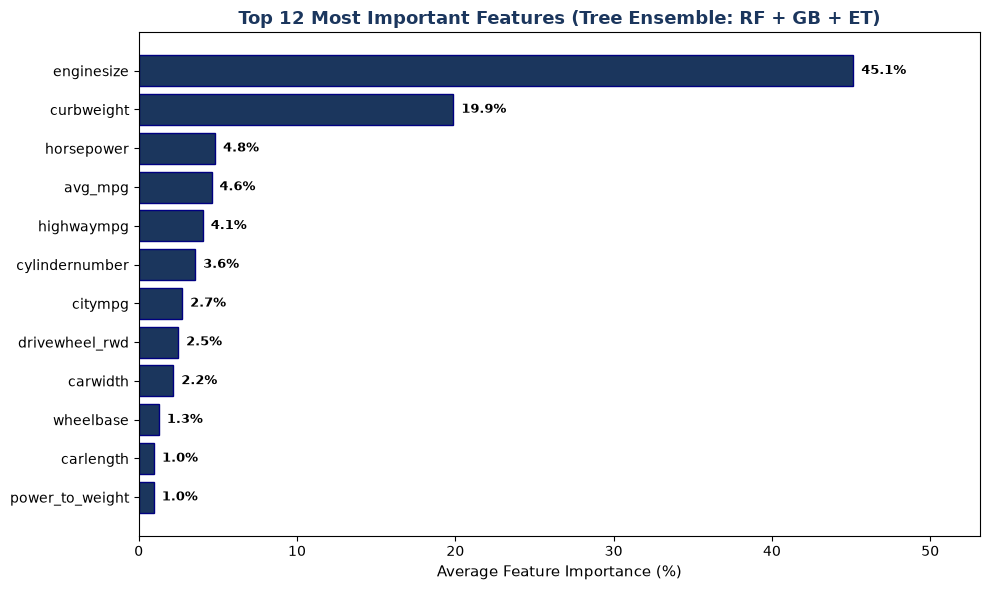

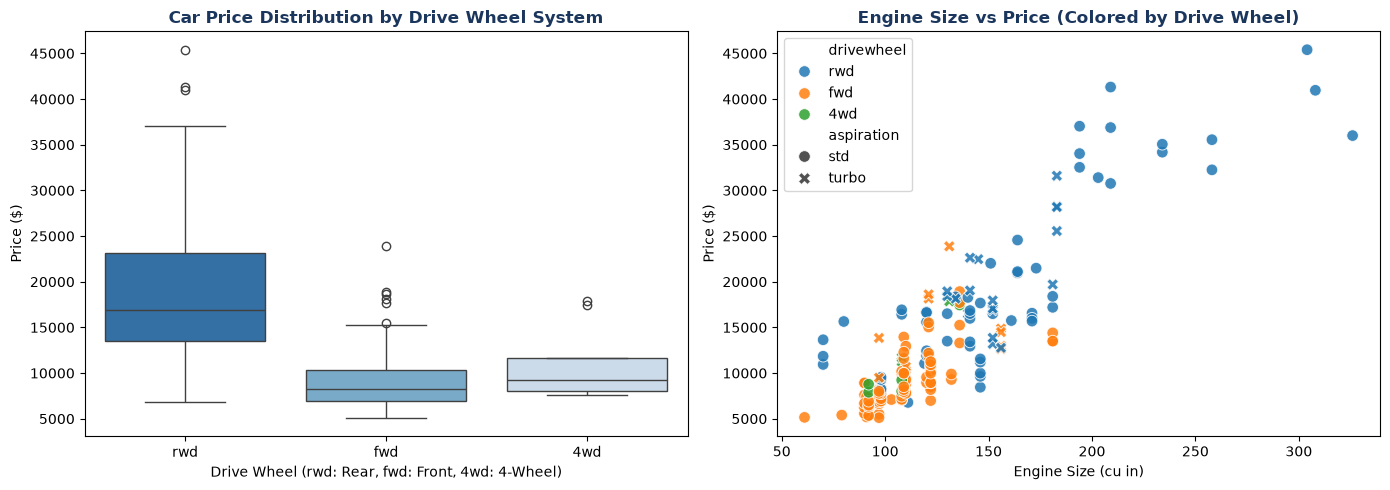

In [6]:
# 5. Additional Visualizations & Feature Diagnostics

# Figure 1: Actual vs Predicted Prices & Residuals (Tree Ensemble)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Menggunakan prediksi dari Voting Regressor (Ensemble)
y_pred_ens = voting_ens.predict(X_test_proc)

sns.scatterplot(
    x=y_test,
    y=y_pred_ens,
    ax=axes[0],
    color='#1B365D',
    s=70,
    alpha=0.8,
    edgecolor='k'
)
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    lw=2,
    label='Ideal Predictor (1:1)'
)
axes[0].set_title(
    'Actual vs Predicted Price (Tree Ensemble)',
    fontsize=12,
    fontweight='bold',
    color='#1B365D'
)
axes[0].set_xlabel('Actual Price ($)', fontsize=10)
axes[0].set_ylabel('Predicted Price ($)', fontsize=10)
axes[0].legend()

# Residual plot berdasarkan prediksi Ensemble
residuals_ens = y_test - y_pred_ens
sns.scatterplot(
    x=y_pred_ens,
    y=residuals_ens,
    ax=axes[1],
    color='#4B6B94',
    s=70,
    alpha=0.8,
    edgecolor='k'
)
axes[1].axhline(0, color='red', linestyle='--', lw=2)
axes[1].set_title('Residual Plot (Prediction Error Distribution)', fontsize=12, fontweight='bold', color='#1B365D')
axes[1].set_xlabel('Predicted Price ($)', fontsize=10)
axes[1].set_ylabel('Residual Error ($)', fontsize=10)

plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=300)
plt.show()

# Figure 2: Top 12 Feature Importances (Tree Ensemble)
encoded_cat_cols = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)
all_feature_names = numerical_cols + list(encoded_cat_cols)

# Menghitung rata-rata pentingnya fitur dari RF, GB, dan ET
ensemble_importances = np.mean([rf.feature_importances_, gb.feature_importances_, et.feature_importances_], axis=0)
importances = pd.Series(ensemble_importances, index=all_feature_names).sort_values(ascending=True).tail(12)

plt.figure(figsize=(10, 6))
bars = plt.barh(importances.index, importances.values * 100, color='#1B365D', edgecolor='navy')
plt.title('Top 12 Most Important Features (Tree Ensemble: RF + GB + ET)', fontsize=13, fontweight='bold', color='#1B365D')
plt.xlabel('Average Feature Importance (%)', fontsize=11)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.5, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', va='center', ha='left', fontsize=9, fontweight='bold')

plt.xlim(0, max(importances.values * 100) + 8)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300)
plt.show()

# Figure 3: Drive Wheel & Engine Size Relationships (Tetap sama karena EDA dasar)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='drivewheel', y='price', hue='drivewheel', palette='Blues_r', legend=False, ax=axes[0])
axes[0].set_title('Car Price Distribution by Drive Wheel System', fontsize=12, fontweight='bold', color='#1B365D')
axes[0].set_xlabel('Drive Wheel (rwd: Rear, fwd: Front, 4wd: 4-Wheel)', fontsize=10)
axes[0].set_ylabel('Price ($)', fontsize=10)

sns.scatterplot(data=df_clean, x='enginesize', y='price', hue='drivewheel', style='aspiration', palette='tab10', s=70, alpha=0.85, ax=axes[1])
axes[1].set_title('Engine Size vs Price (Colored by Drive Wheel)', fontsize=12, fontweight='bold', color='#1B365D')
axes[1].set_xlabel('Engine Size (cu in)', fontsize=10)
axes[1].set_ylabel('Price ($)', fontsize=10)

plt.tight_layout()
plt.savefig('eda_features.png', dpi=300)
plt.show()

## 6. Statistics Reported in the Paper

Dataset exploration figures and the Tree Ensemble residual range quoted in the report.

In [7]:
# 6. Statistics Reported in the Paper (Dataset Exploration, Fig. 1, Residual Analysis)
price = df['price']
print(f"Records: {len(df)} | Price min: {price.min():,.0f} | max: {price.max():,.0f} | mean: {price.mean():,.2f} | median: {price.median():,.0f}")
for col in ['fueltype', 'aspiration', 'carbody', 'drivewheel', 'enginelocation']:
    print(f"{col}: {df[col].value_counts().to_dict()}")

print("\nMean price by drive wheel:", df.groupby('drivewheel')['price'].mean().round(2).to_dict())
print(f"Engine size vs price -> Pearson: {df['enginesize'].corr(price):.4f}, Spearman: {df['enginesize'].corr(price, method='spearman'):.4f}")

residuals_ens = y_test - voting_ens.predict(X_test_proc)
print(f"\nTree Ensemble residuals (n = {len(y_test)}): min {residuals_ens.min():,.2f}, max {residuals_ens.max():,.2f}")

Records: 205 | Price min: 5,118 | max: 45,400 | mean: 13,276.71 | median: 10,295
fueltype: {'gas': 185, 'diesel': 20}
aspiration: {'std': 168, 'turbo': 37}
carbody: {'sedan': 96, 'hatchback': 70, 'wagon': 25, 'hardtop': 8, 'convertible': 6}
drivewheel: {'fwd': 120, 'rwd': 76, '4wd': 9}
enginelocation: {'front': 202, 'rear': 3}

Mean price by drive wheel: {'4wd': 11087.46, 'fwd': 9239.31, 'rwd': 19910.81}
Engine size vs price -> Pearson: 0.8741, Spearman: 0.8260

Tree Ensemble residuals (n = 41): min -4,092.21, max 6,209.97
